# TLS protocol classification v2

This notebook summarizes the v2 model: the rebuilt feature table, the leakage/bias
audit, the grouped cross-validation search, the final frozen-split metrics, and the
robustness checks.

The v2 model is still a **closed-universe** classifier: it distinguishes
`openvpn`, `sstp`, and `both` among servers already in
`H(openvpn_tcp) ∪ H(sstp)`. It is not a VPN-vs-non-VPN detector.

The work is reproducible from the repository root with:

```bash
.venv/bin/python scripts/TLS/tls_clf_v2_build.py
.venv/bin/python scripts/TLS/tls_clf_v2_tune.py all
```

Artifacts live in `tls_clf_v2/`; the Phase 1 audit is in `tls_clf_audit/`.


## What changed from v1

- TLS records use a **best-record merge** (prefer a successful handshake/certificate)
  instead of first-file-wins. This recovers 175 `both` records, including the 171
  cases where the OpenVPN scan failed but the SSTP scan succeeded.
- GET records are selected by best response and then field-filled from the other scan;
  `get_https_response` is now consistent with the status code.
- Certificate age/expired are computed relative to the scan date, not a fixed date.
- Vendor/server/content-type strings are normalized.
- Constants, near-constants, rDNS, ASN, `prefix_len`, raw CN strings, and source
  provenance are excluded from the model.
- Hyperparameters and model structure are selected by **grouped 3-fold CV on the
  training split only**; the frozen validation set is used only for the final check.


In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

BASE = Path.cwd()
V2 = BASE / "tls_clf_v2"
AUDIT = BASE / "tls_clf_audit"
assert V2.is_dir(), f"run from the repository root (cwd={BASE})"
print("base:", BASE.name)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


base: VPN-Auxiliary-Probing


## Feature schema and leakage controls

The schema records which columns are allowed, forbidden, or dropped as redundant.
The forbidden list includes the label components, the semi-leaky OpenVPN UDP
membership, the group keys, the IP identifiers, and the TLS/GET source provenance.


In [2]:
schema = json.loads((V2 / "feature_schema.json").read_text())
print("Allowed model features:", len(schema["allowed_features"]))
print(schema["allowed_features"])
print("\nForbidden columns:")
for c in schema["forbidden_columns"]:
    print(f"  {c}: {schema['forbidden_reasons'].get(c, '')}")


Allowed model features: 23
['handshake_present', 'tls_cipher', 'tls_ocsp_stapling', 'cert_validity_days', 'cert_age_days', 'cert_self_signed', 'cert_cn_is_ipv4', 'cert_cn_has_softether', 'cert_subject_eq_issuer', 'cert_validation_level', 'cert_subject_org', 'cert_issuer_org', 'get_https_probe_status', 'get_https_response', 'get_https_status_class', 'get_https_server', 'get_https_content_type', 'get_https_header_count', 'cert_issuer_org_norm', 'cert_subject_org_norm', 'get_https_server_family', 'get_https_content_type_norm', 'cert_validation_level_norm']

Forbidden columns:
  ip: identifier
  ip_24: identifier
  label: 
  group_cert_fp: grouping key
  group_id: grouping key
  split: 
  in_openvpn_tcp: label component
  in_sstp: label component
  in_openvpn_udp: semi-leaky same-protocol OpenVPN UDP probe
  tls_source: source provenance; perfectly label-correlated
  get_https_source: source provenance
  get_http_source: source provenance
  cert_subject_cn: raw high-cardinality string
  ce

## Feature-set comparison

Candidate sets were compared with grouped 3-fold CV on the training split. The
parsimony rule keeps the smallest set within 0.002 macro-F1 of the best.


In [3]:
fs = pd.read_csv(V2 / "feature_set_results.csv").sort_values("macroF1_mean", ascending=False)
display(fs)


,feature_set,n_features,accuracy_mean,accuracy_std,macroF1_mean,macroF1_std,openvpn_F1_mean,sstp_F1_mean,both_F1_mean
0,full_v2,23,0.975954,0.003024,0.935572,0.012139,0.988960,0.963623,0.854133
1,compact_v2,13,0.975243,0.002755,0.934064,0.012797,0.988634,0.962359,0.851198
2,compact_v2_plus,17,0.974512,0.003066,0.933136,0.014020,0.988112,0.961108,0.850187
3,compact,16,0.950603,0.040651,0.910236,0.041373,0.970592,0.919706,0.840408
4,top_importance,12,0.950438,0.041217,0.910130,0.042780,0.970777,0.918651,0.840962
5,compact_no_availability,13,0.950291,0.040529,0.909997,0.041151,0.970366,0.919071,0.840554


## Hyperparameter search and model structure

`compact_v2` won the parsimony rule. The selected HGB uses 13 features and a
3-class softmax; multi-label and hierarchical variants were compared with the same
grouped CV protocol.


In [4]:
tune = pd.read_csv(V2 / "tuning_results.csv").sort_values("macroF1_mean", ascending=False)
display(tune.head(10)[["config", "macroF1_mean", "macroF1_std", "accuracy_mean",
                       "both_F1_mean", "sstp_F1_mean", "openvpn_F1_mean", "params"]])
struct = pd.read_csv(V2 / "structure_results.csv").sort_values("macroF1_mean", ascending=False)
display(struct)


,config,macroF1_mean,macroF1_std,accuracy_mean,both_F1_mean,sstp_F1_mean,openvpn_F1_mean,params
0,10,0.935016,0.012695,0.975689,0.853094,0.963105,0.988848,"{""learning_rate"": 0.05, ""max_iter"": 400, ""max_..."
1,2,0.934518,0.011971,0.975511,0.851918,0.962866,0.988771,"{""learning_rate"": 0.05, ""max_iter"": 300, ""max_..."
2,4,0.934064,0.012797,0.975243,0.851198,0.962359,0.988634,"{""learning_rate"": 0.1, ""max_iter"": 250, ""max_l..."
3,6,0.933400,0.012365,0.975190,0.849179,0.962321,0.988699,"{""learning_rate"": 0.1, ""max_iter"": 250, ""max_l..."
4,7,0.918239,0.009676,0.968874,0.809879,0.960452,0.984386,"{""learning_rate"": 0.1, ""max_iter"": 250, ""max_l..."
5,0,0.913086,0.042853,0.951389,0.847775,0.920569,0.970915,"{""learning_rate"": 0.05, ""max_iter"": 300, ""max_..."
6,8,0.912604,0.042014,0.951385,0.846281,0.920506,0.971024,"{""learning_rate"": 0.1, ""max_iter"": 150, ""max_l..."
7,11,0.897652,0.042676,0.944690,0.808596,0.918205,0.966154,"{""learning_rate"": 0.05, ""max_iter"": 400, ""max_..."
8,9,0.897526,0.042970,0.944523,0.808095,0.918626,0.965857,"{""learning_rate"": 0.1, ""max_iter"": 150, ""max_l..."
9,1,0.896896,0.042233,0.944363,0.806142,0.918814,0.965731,"{""learning_rate"": 0.05, ""max_iter"": 300, ""max_..."


,structure,accuracy_mean,accuracy_std,macroF1_mean,macroF1_std,both_F1_mean,openvpn_F1_mean,sstp_F1_mean,threshold_mean
0,3class,0.975689,0.002766,0.935016,0.012695,0.853094,0.988848,0.963105,0.500000
1,hierarchical,0.951766,0.041508,0.915175,0.045102,0.853431,0.970885,0.921207,0.400000
2,multilabel,0.952029,0.041053,0.892636,0.082647,0.743296,0.970929,0.963684,0.533333


## Final frozen-split metrics

The model was refit on the full training split and evaluated once on
`validation_10_unseen` and `test_20`.


In [5]:
fm = json.loads((V2 / "final_metrics.json").read_text())
rows = []
for split in ["validation", "test"]:
    m = fm["splits"][split]
    rows.append({"split": split, "accuracy": m["accuracy"], "macroF1": m["macroF1"],
                 "log_loss": m.get("log_loss"), "macro_ovr_auc": m.get("macro_ovr_auc"),
                 "openvpn_F1": m["per_class_F1"]["openvpn"],
                 "sstp_F1": m["per_class_F1"]["sstp"],
                 "both_F1": m["per_class_F1"]["both"]})
display(pd.DataFrame(rows))
display(pd.DataFrame(fm["splits"]["validation"]["subgroups"]).T)
display(pd.DataFrame(fm["splits"]["test"]["subgroups"]).T)


,split,accuracy,macroF1,log_loss,macro_ovr_auc,openvpn_F1,sstp_F1,both_F1
0,validation,0.984869,0.955888,0.055864,0.996897,0.993487,0.977526,0.896650
1,test,0.979845,0.937675,0.065475,0.996361,0.991705,0.971564,0.849755


,n,accuracy,macroF1,per_class_F1
all,64105,0.984869,0.955888,"{'openvpn': 0.9934872054390635, 'sstp': 0.9775..."
tls_handshake_true,45336,0.984802,0.959382,"{'openvpn': 0.9942185786254717, 'sstp': 0.9861..."
tls_handshake_false,18769,0.985029,0.450025,"{'openvpn': 0.9924268966446571, 'sstp': 0.3576..."
get_https_response_true,41859,0.983779,0.958343,"{'openvpn': 0.9943445502884092, 'sstp': 0.9828..."
get_https_response_false,22246,0.986919,0.650238,"{'openvpn': 0.9922760451227605, 'sstp': 0.9584..."


,n,accuracy,macroF1,per_class_F1
all,128206,0.979845,0.937675,"{'openvpn': 0.9917045523261887, 'sstp': 0.9715..."
tls_handshake_true,93714,0.978957,0.941864,"{'openvpn': 0.9920192874552349, 'sstp': 0.9806..."
tls_handshake_false,34492,0.982257,0.381449,"{'openvpn': 0.9911805209645755, 'sstp': 0.1531..."
get_https_response_true,87840,0.97755,0.940145,"{'openvpn': 0.9920686148812945, 'sstp': 0.9763..."
get_https_response_false,40366,0.984839,0.647466,"{'openvpn': 0.991106202406557, 'sstp': 0.95129..."


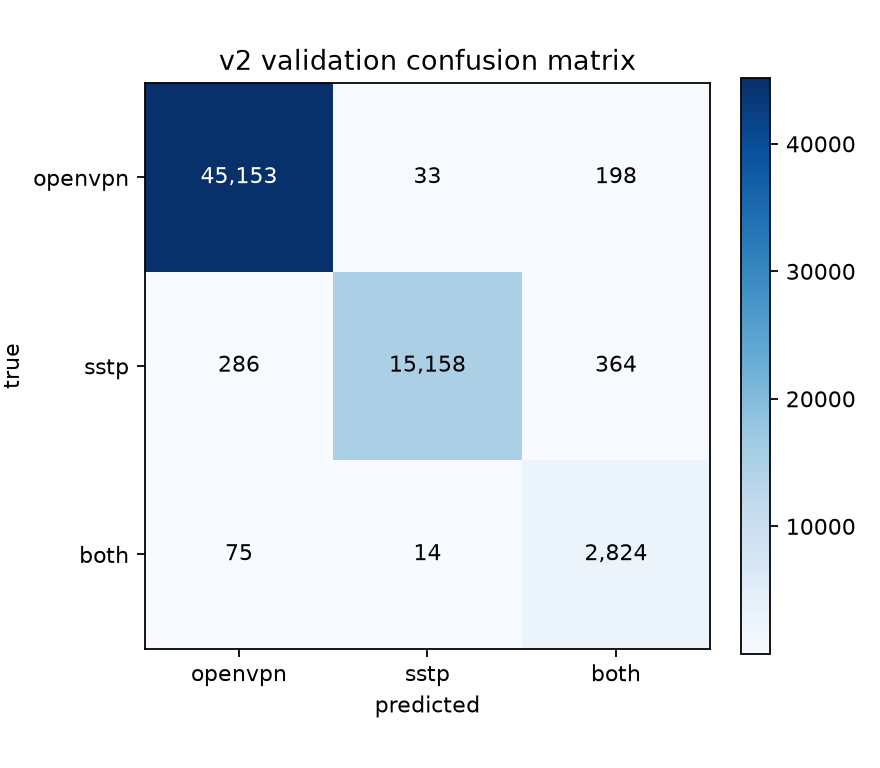

In [6]:
display(Image(filename=str(V2 / "confusion_matrix_validation.png")))


## Permutation importance

Permutation importance on the frozen validation set. Correlated features share
importance; zero/negative values usually mean redundancy rather than “no signal.”


,feature,mean_drop_macroF1,std
0,get_https_header_count,0.178777,0.004104
1,get_https_server,0.153681,0.002525
2,tls_ocsp_stapling,0.057541,0.001328
3,tls_cipher,0.056257,0.000862
4,cert_subject_org_norm,0.054562,0.001990
5,get_https_content_type,0.041827,0.001198
6,cert_validity_days,0.016707,0.000997
7,get_https_status_class,0.014120,0.000358
8,cert_issuer_org_norm,0.009144,0.000474
9,get_https_probe_status,0.008374,0.000210


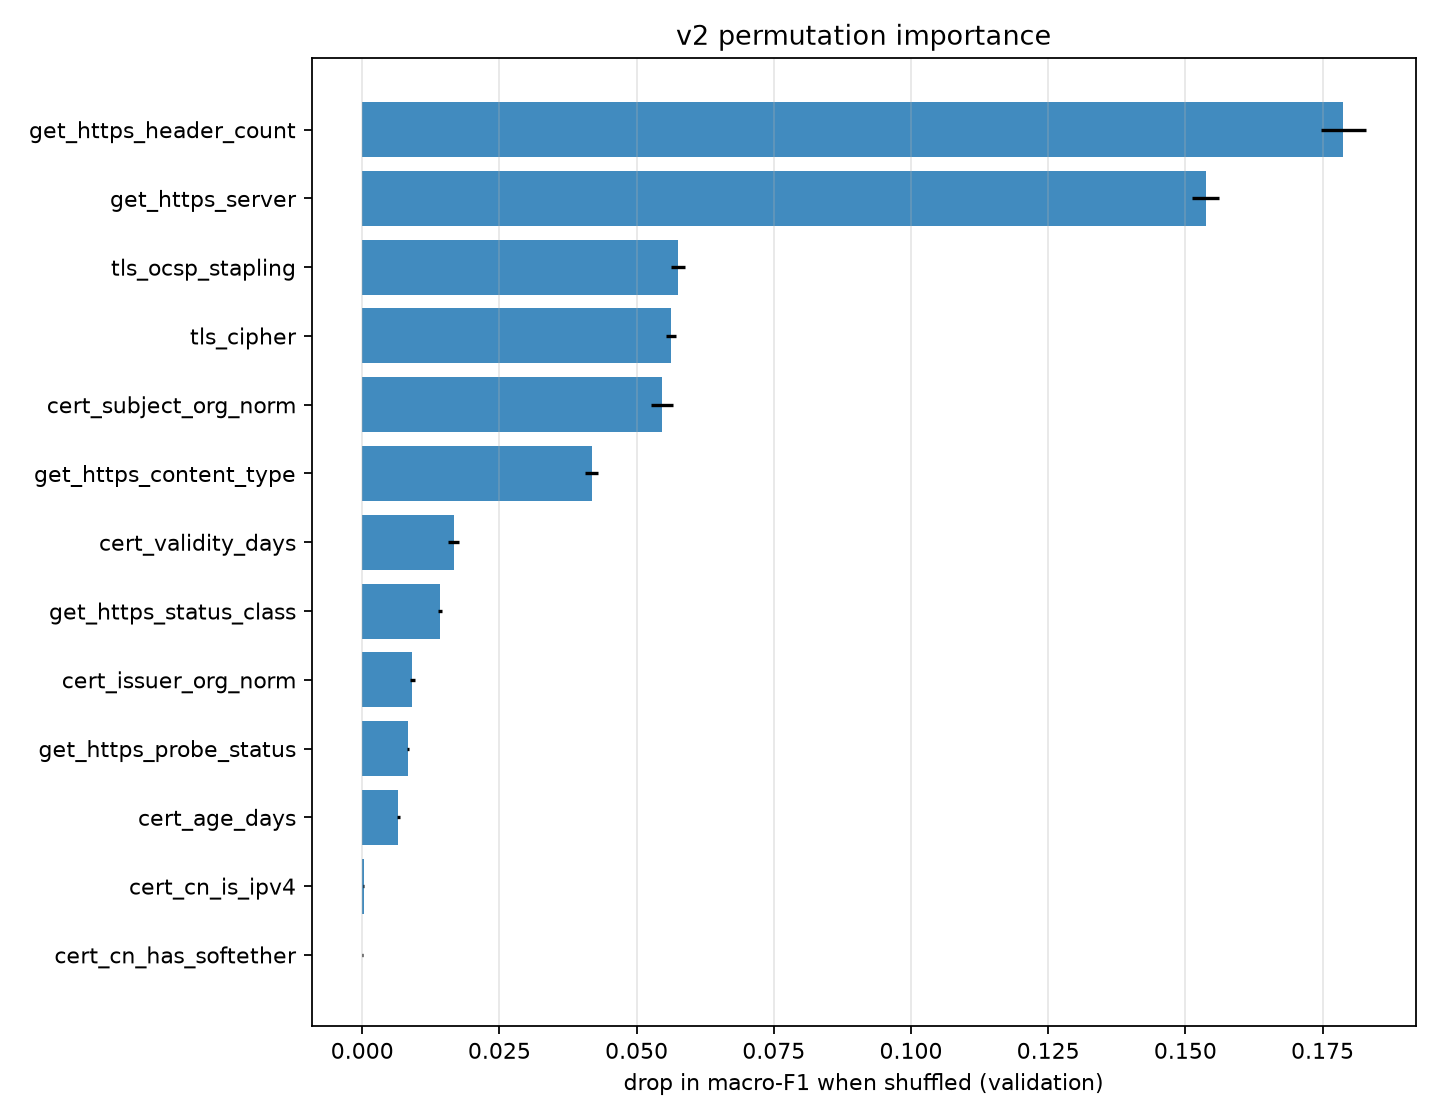

In [7]:
imp = pd.read_csv(V2 / "permutation_importance.csv")
display(imp.head(15))
display(Image(filename=str(V2 / "permutation_importance.png")))


## Robustness checks

The label-permutation test should fall to the majority baseline. The leave-ASN-out
test holds out 20% of ASNs; leave-vendor-out holds out one issuer at a time. Vendor
subsets with only one class present have a misleading macro-F1, so read the accuracy
and per-class F1 in `robustness.json` alongside the table.

The unseen-fingerprint subset is the important check here: it measures rows
whose exact 13-feature vector does not appear in the training split, so the model
cannot rely on a train twin.


In [8]:
rob = json.loads((V2 / "robustness.json").read_text())
print("Label permutation:")
display(pd.DataFrame([rob["label_permutation"]]))
if rob.get("leave_vendor_out"):
    display(pd.DataFrame([
        {"vendor": k, "n_validation": v["n_validation"], "accuracy": v["accuracy"],
         "macroF1": v["macroF1"], "both_F1": v["per_class_F1"]["both"]}
        for k, v in rob["leave_vendor_out"].items()
    ]))
if rob.get("leave_asn_out"):
    display(pd.DataFrame([rob["leave_asn_out"]]))

if rob.get("unseen_fingerprint"):
    rows = []
    for split, entry in rob["unseen_fingerprint"].items():
        for subset in ["all", "seen_fingerprint", "unseen_fingerprint"]:
            if subset not in entry:
                continue
            e = entry[subset]
            rows.append({"split": split, "subset": subset, "n": e["n"],
                         "accuracy": e["accuracy"], "macroF1": e["macroF1"],
                         "both_F1": e["per_class_F1"]["both"]})
    display(pd.DataFrame(rows))


Label permutation:


,accuracy,macroF1,per_class_F1,log_loss,macro_ovr_auc
0,0.707963,0.276338,"{'openvpn': 0.8290147868735672, 'sstp': 0.0, '...",0.730913,0.441107


,vendor,n_validation,accuracy,macroF1,both_F1
0,watchguard,17216,0.999942,0.333324,0.000000
1,digicert,5494,0.995268,0.815212,0.461538
2,sectigo,3335,0.973913,0.689804,0.093023
3,stormshield,1149,0.999130,0.333188,0.000000
4,letsencrypt,1560,0.935897,0.771216,0.391304


,accuracy,macroF1,per_class_F1,log_loss,macro_ovr_auc,n_train,n_validation,n_holdout_asns
0,0.988504,0.955345,"{'openvpn': 0.9941346551011978, 'sstp': 0.9867...",0.046239,0.997487,390999,8351,2714


,split,subset,n,accuracy,macroF1,both_F1
0,validation,all,64105,0.984869,0.955888,0.896650
1,validation,seen_fingerprint,43311,0.992242,0.840371,0.548148
2,validation,unseen_fingerprint,20794,0.969510,0.955456,0.904283
3,test,all,128206,0.979845,0.937675,0.849755
4,test,seen_fingerprint,88989,0.990111,0.832485,0.526965
5,test,unseen_fingerprint,39217,0.956549,0.937709,0.867217


## Using the saved model

The model bundle contains the fitted estimator(s), the category maps, the selected
feature list, the structure, and the decision threshold.


In [9]:
bundle = joblib.load(V2 / "model.joblib")
print("structure:", bundle["structure"])
print("features:", bundle["features"])
print("params:", bundle["params"])

CAT_K = schema["categorical_features"]

def build_xy(frame, cols, maps):
    X = pd.DataFrame(index=frame.index)
    for c in cols:
        if c in CAT_K:
            s = frame[c].astype("object").where(frame[c].notna(), None)
            code = s.map(maps[c])
            X[c] = np.where(s.isna(), 0, code.fillna(len(maps[c]) + 1)).astype("int32")
        else:
            X[c] = pd.to_numeric(frame[c], errors="coerce").astype("float32")
    return X

model_path = V2 / "features_model.csv"
if not model_path.exists():
    model_path = V2 / "features_model.csv.gz"
model_df = pd.read_csv(model_path, low_memory=False,
                       dtype={"ip": "string", "group_id": "string"})
val = model_df[model_df["split"] == "validation"].reset_index(drop=True)
X = build_xy(val, bundle["features"], bundle["maps"])
pred = bundle["model"].predict(X)
print("validation rows:", len(val))
print("validation accuracy:", round(float((pred == val["label"].map({"openvpn": 0, "sstp": 1, "both": 2})).mean()), 4))


structure: 3class
features: ['tls_cipher', 'tls_ocsp_stapling', 'cert_age_days', 'cert_validity_days', 'cert_issuer_org_norm', 'cert_subject_org_norm', 'cert_cn_is_ipv4', 'cert_cn_has_softether', 'get_https_probe_status', 'get_https_status_class', 'get_https_server', 'get_https_content_type', 'get_https_header_count']
params: {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 100, 'l2_regularization': 0.1, 'class_weight': None}


validation rows: 64105
validation accuracy: 0.9849


## Where is the model-fitting code?

The notebook is intentionally a **report/summary notebook**: it loads the fitted
artifacts so it stays fast to open and run. The code that actually builds the
feature table and fits/tunes the models lives in the scripts below.

- `scripts/TLS/tls_clf_v2_build.py` — streams the raw TLS/GET/rDNS/ASN files,
  performs the best-record merges, normalizes strings, writes the v2 tables and
  the feature schema.
- `scripts/TLS/tls_clf_v2_tune.py` — grouped 3-fold CV, feature-set comparison,
  hyperparameter search, model-structure comparison, final fit, metrics,
  permutation importance, and robustness checks.
- `scripts/TLS/tls_clf_v2_duplicates.py` — duplicate-feature-vector check.

The next cell prints the core functions directly from the tuning script, so the
exact code is visible here as well.


In [10]:
import inspect
import sys

sys.path.insert(0, str(BASE / "scripts/TLS"))
import tls_clf_v2_tune as tune

print("compact_v2 features:")
print(tune.FEATURE_SETS["compact_v2"])
print("\nDEFAULT_PARAMS:")
print(tune.DEFAULT_PARAMS)
print("\nSelected params:")
print(json.loads((V2 / "best_config.json").read_text())["params"])

for fn in [tune.model_kwargs, tune.build_xy, tune.fit_bundle, tune.get_folds,
           tune.stage_tune, tune.stage_structure]:
    print("\n" + "=" * 100)
    print(inspect.getsource(fn))


compact_v2 features:
['tls_cipher', 'tls_ocsp_stapling', 'cert_age_days', 'cert_validity_days', 'cert_issuer_org_norm', 'cert_subject_org_norm', 'cert_cn_is_ipv4', 'cert_cn_has_softether', 'get_https_probe_status', 'get_https_status_class', 'get_https_server', 'get_https_content_type', 'get_https_header_count']

DEFAULT_PARAMS:
{'learning_rate': 0.1, 'max_iter': 250, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 0.0, 'class_weight': None}

Selected params:
{'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 100, 'l2_regularization': 0.1, 'class_weight': None}

def model_kwargs(params: dict, cat_idx: list[int]) -> dict:
    kw = dict(
        learning_rate=params.get("learning_rate", 0.1),
        max_iter=params.get("max_iter", 250),
        max_leaf_nodes=params.get("max_leaf_nodes", 31),
        min_samples_leaf=params.get("min_samples_leaf", 20),
        l2_regularization=params.get("l2_regularization", 0.0),
        early_stopping

To rerun the full pipeline from scratch:

```bash
.venv/bin/python scripts/TLS/tls_clf_v2_build.py
.venv/bin/python scripts/TLS/tls_clf_v2_tune.py all
```

The first command streams the raw scans and takes roughly two minutes in this
environment; the second runs the feature-set comparison, hyperparameter search,
structure comparison, final fit, robustness checks, and report generation.


## Known limitations

- The universe is positives-only: there are no ordinary HTTPS negatives, so this is
  not a VPN detector.
- Labels come from the two protocol probes; probe failure is part of the target.
- Much of the signal is vendor/software fingerprinting. Expect drift across firmware
  versions, default-certificate changes, and web-UI changes.
- The split is grouped by certificate/ /24, not by time, ASN, or vendor. The
  leave-ASN-out and leave-vendor-out checks quantify part of that gap.
- `both` is heavily SoftEther/multi-protocol; it is not a clean ground-truth
  “supports both protocols” label.

See `tls_clf_audit/PHASE1_FINDINGS.md` and `tls_clf_v2/V2_REPORT.md` for the full
discussion.
